# COVID-19 Global Data Analysis — Project 2
### Exploratory Data Analysis & Visualization using Python (Pandas, Matplotlib & Seaborn)

**Project Overview:**  
End-to-end exploratory data analysis (EDA) on global COVID-19 data across **225 countries and territories**, covering data inspection, missing-value handling, summary statistics, top/bottom country rankings, continent-level aggregation, and correlation analysis.

## Part 1: Setup & Initial Data Inspection
### 1. Import required libraries and load the dataset

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

sns.set_theme(style='whitegrid')
df = pd.read_csv('COVID-19 Coronavirus.csv')
print('Dataset loaded successfully!')

Dataset loaded successfully!


### 2. Display the shape of the dataset

In [2]:
print(f'Rows: {df.shape[0]}, Columns: {df.shape[1]}')
df.shape

Rows: 225, Columns: 10


(225, 10)

### 3. Display the first five rows of the dataset

In [3]:
df.head()

,Country,Other names,ISO 3166-1 alpha-3 CODE,Population,Continent,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
0,Afghanistan,Afghanistan,AFG,40462186,Asia,177827,7671,4395,190,4.313743
1,Albania,Albania,ALB,2872296,Europe,273870,3492,95349,1216,1.275058
2,Algeria,Algeria,DZA,45236699,Africa,265691,6874,5873,152,2.587216
3,Andorra,Andorra,AND,77481,Europe,40024,153,516565,1975,0.382271
4,Angola,Angola,AGO,34654212,Africa,99194,1900,2862,55,1.915438


### 4. Display the last five rows of the dataset

In [4]:
df.tail()

,Country,Other names,ISO 3166-1 alpha-3 CODE,Population,Continent,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
220,Wallis and Futuna,Wallis and Futuna Islands,WLF,10894,Oceania,454,7,41674,643,1.541850
221,Western Sahara,Western Sahara,ESHÂ,623031,Africa,10,1,16,2,10.000000
222,Yemen,Yemen,YEM,30975258,Asia,11806,2143,381,69,18.151787
223,Zambia,Zambia,ZMB,19284482,Africa,317076,3967,16442,206,1.251120
224,Zimbabwe,Zimbabwe,ZWE,15241601,Africa,246525,5446,16174,357,2.209107


### 5. Display the information of the dataset, including column names and data types

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225 entries, 0 to 224
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Country                  225 non-null    object 
 1   Other names              224 non-null    object 
 2   ISO 3166-1 alpha-3 CODE  225 non-null    object 
 3   Population               225 non-null    int64  
 4   Continent                225 non-null    object 
 5   Total Cases              225 non-null    int64  
 6   Total Deaths             225 non-null    int64  
 7   Tot Cases//1M pop        225 non-null    int64  
 8   Tot Deaths/1M pop        225 non-null    int64  
 9   Death percentage         225 non-null    float64
dtypes: float64(1), int64(5), object(4)
memory usage: 17.7+ KB


**Observation (Part 1):**  
- The dataset contains **225 rows** (countries/territories) and **10 columns**.
- There are **4 text (`object`) columns** and **6 numerical columns** (`5 int64` and `1 float64`).

## Part 2: Data Cleaning & Statistical Summary
### 6. Check the missing values in each column

In [6]:
df.isnull().sum()

Country                    0
Other names                1
ISO 3166-1 alpha-3 CODE    0
Population                 0
Continent                  0
Total Cases                0
Total Deaths               0
Tot Cases//1M pop          0
Tot Deaths/1M pop          0
Death percentage           0
dtype: int64

### 7. Display the row(s) that contain missing values

In [7]:
df[df.isnull().any(axis=1)]

,Country,Other names,ISO 3166-1 alpha-3 CODE,Population,Continent,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
135,Montenegro,NaN,MNE,628205,Europe,233326,2705,371417,4306,1.159322


### 8. Replace the missing value with 'Montenegro'

In [8]:
df['Other names'] = df['Other names'].fillna('Montenegro')
print('Missing values remaining:', df.isnull().sum().sum())

Missing values remaining: 0


### 9. Check row 135 to verify whether the missing value has been replaced

In [9]:
df.iloc[135]

Country                    Montenegro
Other names                Montenegro
ISO 3166-1 alpha-3 CODE           MNE
Population                     628205
Continent                      Europe
Total Cases                    233326
Total Deaths                     2705
Tot Cases//1M pop              371417
Tot Deaths/1M pop                4306
Death percentage             1.159322
Name: 135, dtype: object

### 10. Generate the descriptive statistical summary of the dataset

In [10]:
df.describe().round(2)

,Population,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
count,2.250000e+02,225.00,225.00,225.00,225.00,225.00
mean,3.507321e+07,2184781.45,27448.13,136900.37,1096.72,1.44
std,1.392418e+08,7275937.88,96891.77,145060.34,1195.72,1.74
min,8.050000e+02,1.00,0.00,9.00,0.00,0.00
25%,5.665570e+05,24071.00,189.00,11384.00,123.00,0.51
50%,5.827911e+06,163936.00,1965.00,88987.00,708.00,1.04
75%,2.190585e+07,1092547.00,13660.00,223335.00,1795.00,1.98
max,1.439324e+09,81839052.00,1008222.00,696044.00,6286.00,18.15


### 11. Rename 'ISO 3166-1 alpha-3 CODE' to 'Iso_Code' and display the first four rows

In [11]:
df.rename(columns={'ISO 3166-1 alpha-3 CODE': 'Iso_Code'}, inplace=True)
df.head(4)

,Country,Other names,Iso_Code,Population,Continent,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
0,Afghanistan,Afghanistan,AFG,40462186,Asia,177827,7671,4395,190,4.313743
1,Albania,Albania,ALB,2872296,Europe,273870,3492,95349,1216,1.275058
2,Algeria,Algeria,DZA,45236699,Africa,265691,6874,5873,152,2.587216
3,Andorra,Andorra,AND,77481,Europe,40024,153,516565,1975,0.382271


**Observation (Part 2):**  
- Only **1 missing value** existed in the dataset (row `135`, **Montenegro**, in the `Other names` column), which was replaced with `'Montenegro'`.
- The data is strongly right-skewed: mean cases (**2.18M**) are more than **13x higher** than median cases (**163,936**), showing that a handful of large nations account for most global infections.

## Part 3: Country-Level Rankings & Visualizations
### 12. Find the five countries that have the highest number of COVID-19 cases

In [12]:
top5_cases = df.sort_values(by='Total Cases', ascending=False).head(5)
top5_cases[['Country', 'Continent', 'Total Cases', 'Total Deaths', 'Death percentage']]

,Country,Continent,Total Cases,Total Deaths,Death percentage
214,USA,Northern America,81839052,1008222,1.231957
92,India,Asia,43029044,521388,1.211712
26,Brazil,Latin America and the Caribbean,29999816,660269,2.200910
70,France,Europe,25997852,142506,0.548145
76,Germany,Europe,21646375,130563,0.603163


### 13. Create a bar plot showing the top five countries with the highest total COVID-19 cases

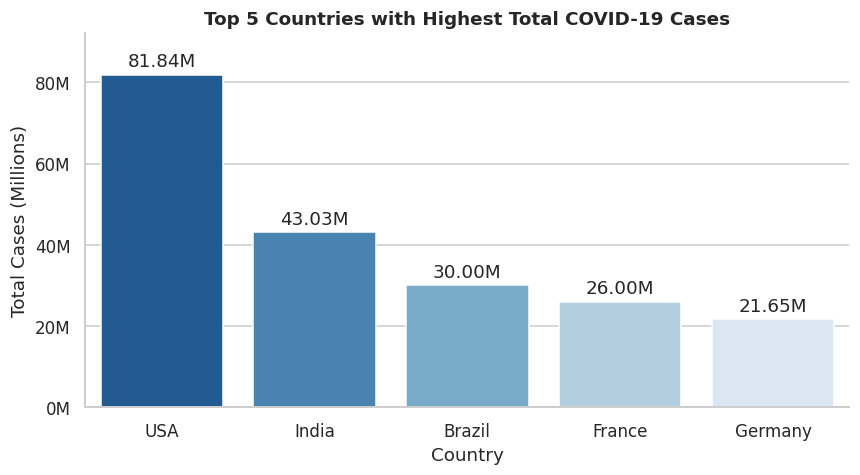

In [13]:
plt.figure(figsize=(8, 4.5))
ax = sns.barplot(data=top5_cases, x='Country', y='Total Cases', palette='Blues_r')
plt.title('Top 5 Countries with Highest Total COVID-19 Cases', fontsize=12, fontweight='bold')
plt.xlabel('Country')
plt.ylabel('Total Cases (Millions)')
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x/1e6:.0f}M'))
plt.ylim(0, 92000000)
for c in ax.containers:
    ax.bar_label(c, labels=[f'{v/1e6:.2f}M' for v in top5_cases['Total Cases']], padding=3)
sns.despine()
plt.tight_layout()
plt.show()

### 14. Find the five countries that have the lowest number of COVID-19 cases

In [14]:
low5_cases = df.sort_values(by='Total Cases', ascending=True).head(5)
low5_cases[['Country', 'Continent', 'Population', 'Total Cases']]

,Country,Continent,Population,Total Cases
131,Micronesia,Oceania,117134,1
168,Saint Helena,Africa,6109,2
148,Niue,Oceania,1645,7
125,Marshall Islands,Oceania,59889,7
221,Western Sahara,Africa,623031,10


### 15. Create a bar plot showing the five countries with the lowest total COVID-19 cases

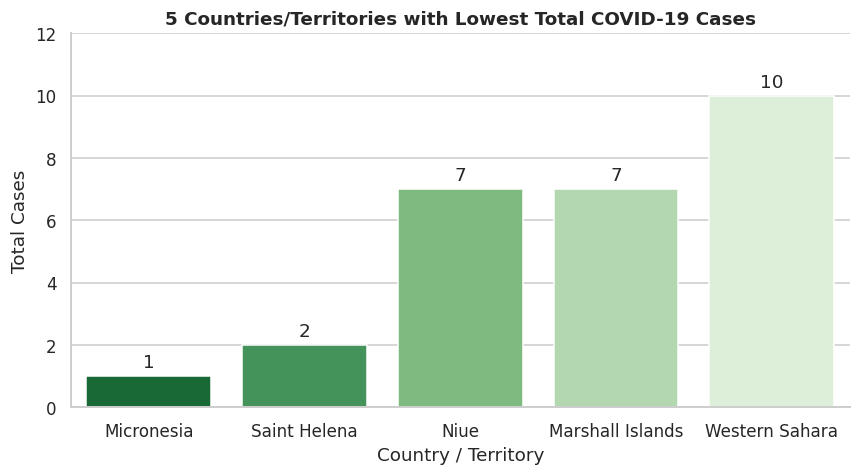

In [15]:
plt.figure(figsize=(8, 4.5))
ax = sns.barplot(data=low5_cases, x='Country', y='Total Cases', palette='Greens_r')
plt.title('5 Countries/Territories with Lowest Total COVID-19 Cases', fontsize=12, fontweight='bold')
plt.xlabel('Country / Territory')
plt.ylabel('Total Cases')
plt.ylim(0, 12)
for c in ax.containers:
    ax.bar_label(c, padding=3)
sns.despine()
plt.tight_layout()
plt.show()

### 16. Find the five countries that have the highest number of COVID-19 deaths

In [16]:
top5_deaths = df.sort_values(by='Total Deaths', ascending=False).head(5)
top5_deaths[['Country', 'Continent', 'Total Deaths', 'Total Cases', 'Death percentage']]

,Country,Continent,Total Deaths,Total Cases,Death percentage
214,USA,Northern America,1008222,81839052,1.231957
26,Brazil,Latin America and the Caribbean,660269,29999816,2.200910
92,India,Asia,521388,43029044,1.211712
165,Russia,Europe,369708,17896866,2.065770
130,Mexico,Latin America and the Caribbean,323212,5665376,5.705041


### 17. Create a bar plot showing the top five countries with the highest total COVID-19 deaths

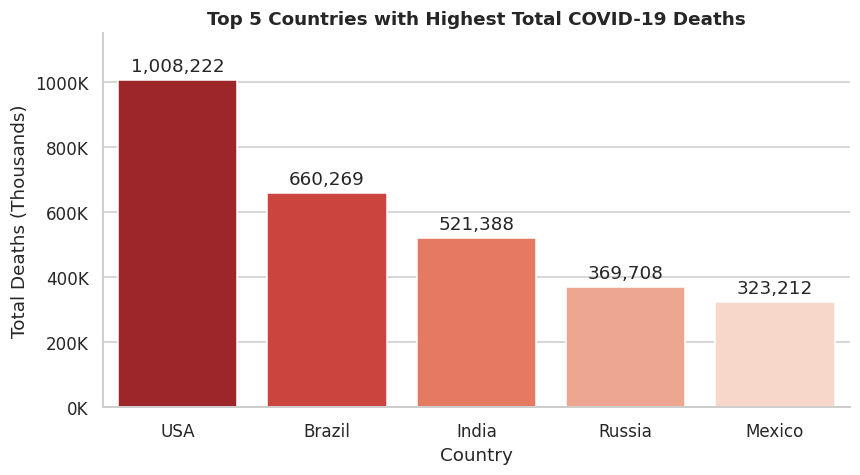

In [17]:
plt.figure(figsize=(8, 4.5))
ax = sns.barplot(data=top5_deaths, x='Country', y='Total Deaths', palette='Reds_r')
plt.title('Top 5 Countries with Highest Total COVID-19 Deaths', fontsize=12, fontweight='bold')
plt.xlabel('Country')
plt.ylabel('Total Deaths (Thousands)')
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x/1e3:.0f}K'))
plt.ylim(0, 1150000)
for c in ax.containers:
    ax.bar_label(c, labels=[f'{v:,.0f}' for v in top5_deaths['Total Deaths']], padding=3)
sns.despine()
plt.tight_layout()
plt.show()

### 18. Find the five countries that have the lowest number of COVID-19 deaths

In [18]:
low5_deaths = df.sort_values(by='Total Deaths', ascending=True).head(5)
low5_deaths[['Country', 'Continent', 'Total Cases', 'Total Deaths']]

,Country,Continent,Total Cases,Total Deaths
168,Saint Helena,Africa,2,0
118,Macao,Asia,82,0
217,Vatican City,Europe,29,0
131,Micronesia,Oceania,1,0
67,Falkland Islands,Latin America and the Caribbean,123,0


### 19. Find the five countries with the highest COVID-19 death percentage

In [19]:
top5_death_pct = df.sort_values(by='Death percentage', ascending=False).head(5)
top5_death_pct[['Country', 'Continent', 'Total Cases', 'Total Deaths', 'Death percentage']]

,Country,Continent,Total Cases,Total Deaths,Death percentage
222,Yemen,Asia,11806,2143,18.151787
221,Western Sahara,Africa,10,1,10.000000
193,Sudan,Africa,61955,4907,7.920265
158,Peru,Latin America and the Caribbean,3548559,212328,5.983499
130,Mexico,Latin America and the Caribbean,5665376,323212,5.705041


### 20. Create a bar plot showing the top five countries with the highest COVID-19 death percentage

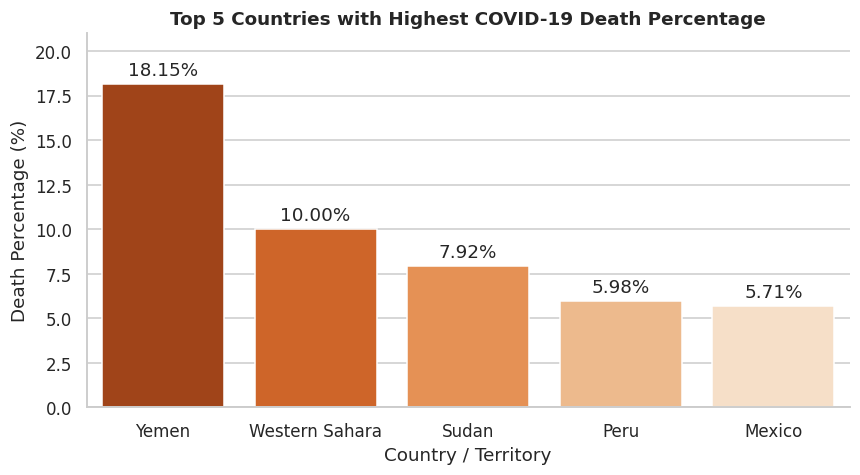

In [20]:
plt.figure(figsize=(8, 4.5))
ax = sns.barplot(data=top5_death_pct, x='Country', y='Death percentage', palette='Oranges_r')
plt.title('Top 5 Countries with Highest COVID-19 Death Percentage', fontsize=12, fontweight='bold')
plt.xlabel('Country / Territory')
plt.ylabel('Death Percentage (%)')
plt.ylim(0, 21)
for c in ax.containers:
    ax.bar_label(c, labels=[f'{v:.2f}%' for v in top5_death_pct['Death percentage']], padding=3)
sns.despine()
plt.tight_layout()
plt.show()

**Observation (Part 3):**  
- The top 5 countries (**USA, India, Brazil, France, Germany**) account for **41.20%** of all global cases, while the top 5 mortality countries (**USA, Brazil, India, Russia, Mexico**) account for **46.68%** of all global deaths.
- **Yemen** (`18.15%`) and **Sudan** (`7.92%`) recorded the highest fatality rates among major countries, whereas **France** (`0.55%`) and **Germany** (`0.60%`) had low fatality percentages despite high case counts.

## Part 4: Continent-Wise Analysis & Correlations
### 21. Calculate the total COVID-19 cases continent-wise using groupby()

In [21]:
continent_cases = df.groupby('Continent')['Total Cases'].sum()
continent_cases

Continent
Africa                              11764207
Asia                               140957179
Europe                             180332483
Latin America and the Caribbean     67509231
Northern America                    85364770
Oceania                              5647957
Name: Total Cases, dtype: int64

### 22. Reset the index of the continent-wise result and create a bar plot showing total COVID-19 cases by continent

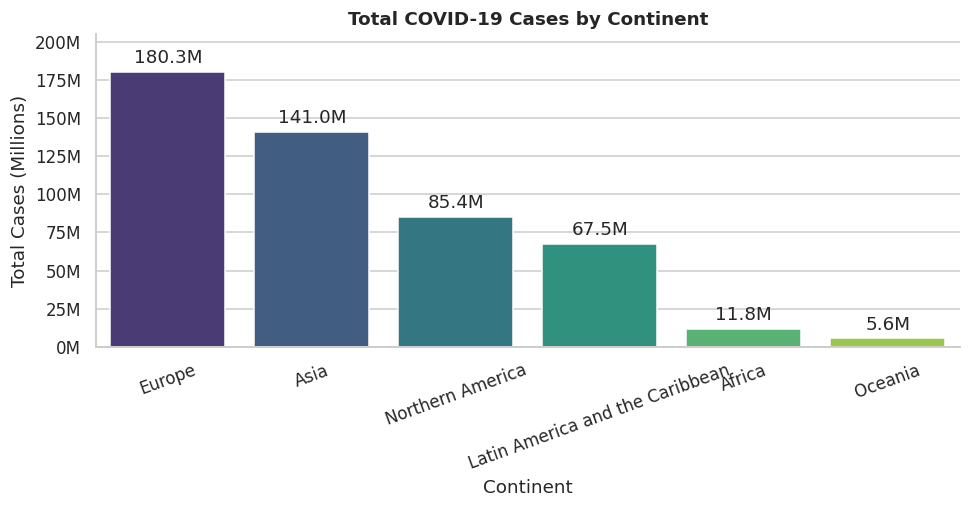

In [22]:
continent_cases_df = continent_cases.reset_index().sort_values(by='Total Cases', ascending=False)

plt.figure(figsize=(9, 4.8))
ax = sns.barplot(data=continent_cases_df, x='Continent', y='Total Cases', palette='viridis')
plt.title('Total COVID-19 Cases by Continent', fontsize=12, fontweight='bold')
plt.xlabel('Continent')
plt.ylabel('Total Cases (Millions)')
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x/1e6:.0f}M'))
plt.ylim(0, 205000000)
plt.xticks(rotation=20)
for c in ax.containers:
    ax.bar_label(c, labels=[f'{v/1e6:.1f}M' for v in continent_cases_df['Total Cases']], padding=3)
sns.despine()
plt.tight_layout()
plt.show()

### 23. Create a scatter plot to show the relationship between Population and Total Cases

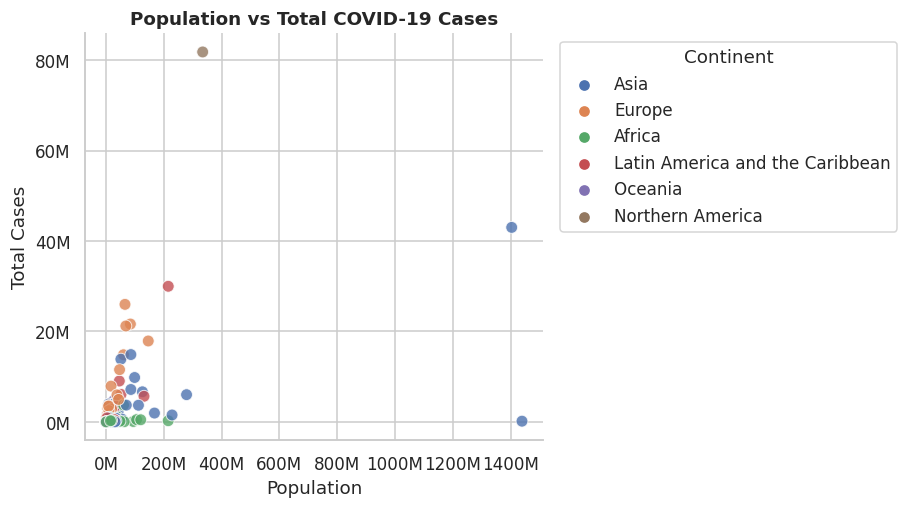

In [23]:
plt.figure(figsize=(8.5, 4.8))
ax = sns.scatterplot(data=df, x='Population', y='Total Cases', hue='Continent', alpha=0.8, s=60)
plt.title('Population vs Total COVID-19 Cases', fontsize=12, fontweight='bold')
plt.xlabel('Population')
plt.ylabel('Total Cases')
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x/1e6:.0f}M'))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x/1e6:.0f}M'))
plt.legend(title='Continent', bbox_to_anchor=(1.02, 1), loc='upper left')
sns.despine()
plt.tight_layout()
plt.show()

### 24. Create a scatter plot to show the relationship between Total Cases and Total Deaths

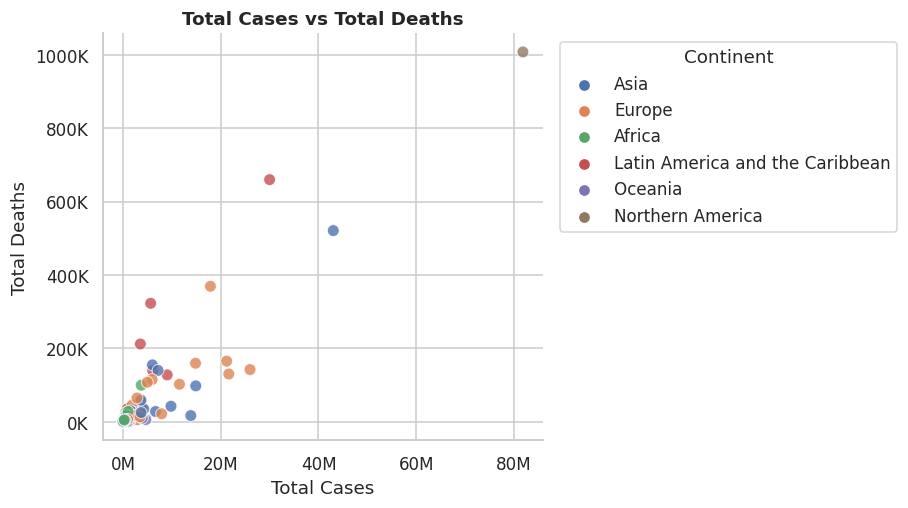

In [24]:
plt.figure(figsize=(8.5, 4.8))
ax = sns.scatterplot(data=df, x='Total Cases', y='Total Deaths', hue='Continent', alpha=0.8, s=60)
plt.title('Total Cases vs Total Deaths', fontsize=12, fontweight='bold')
plt.xlabel('Total Cases')
plt.ylabel('Total Deaths')
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x/1e6:.0f}M'))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x/1e3:.0f}K'))
plt.legend(title='Continent', bbox_to_anchor=(1.02, 1), loc='upper left')
sns.despine()
plt.tight_layout()
plt.show()

### 25. Calculate the Spearman rank correlation for the numerical columns and visualize the correlation matrix using a heatmap

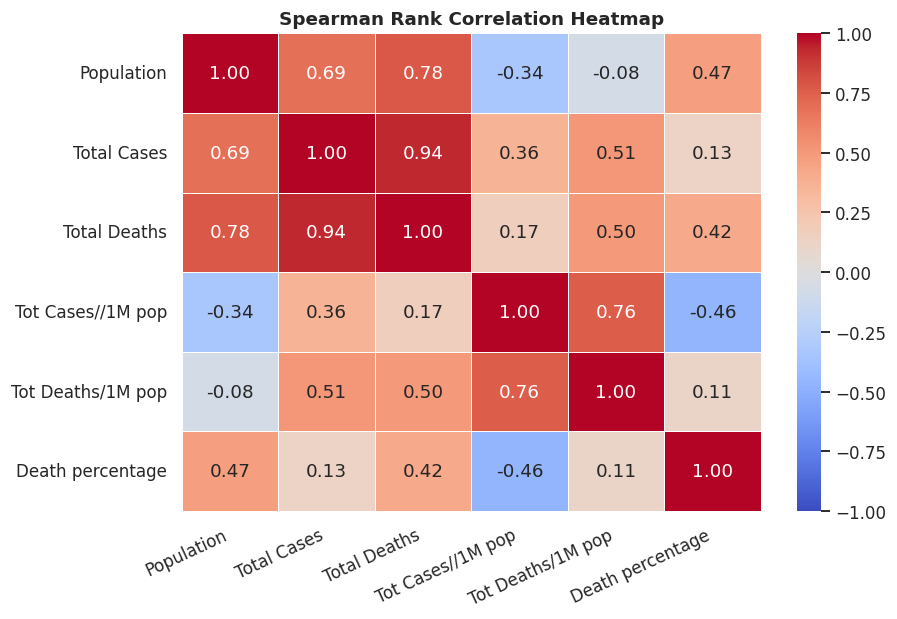

In [25]:
spearman_corr = df.corr(method='spearman', numeric_only=True)

plt.figure(figsize=(8.5, 5.8))
sns.heatmap(spearman_corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Spearman Rank Correlation Heatmap', fontsize=12, fontweight='bold')
plt.xticks(rotation=25, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Observation (Part 4):**  
- **Europe** (`180.33M`) and **Asia** (`140.96M`) together account for **65.35%** of all global cases.
- **Total Cases vs. Total Deaths (`r = 0.94`):** Very strong positive Spearman correlation, confirming that cumulative deaths scale closely with total infections.
- **Testing Effect (`r = -0.46`):** `Tot Cases//1M pop` correlates negatively with `Death percentage`, showing that higher testing per million detects milder cases and lowers the observed fatality rate.